# Лабораторная 02 — Аугментация данных и устойчивость

Юдин Артём

### 0. Импорты

In [2]:
import sys
import librosa
import numpy as np
import pandas as pd
import soundfile as sf
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

#### Начальные шаги

In [3]:
aug_dir = Path("outputs/augmented")
fig_dir = Path("outputs/figures")

plt.rcParams["figure.dpi"] = 300

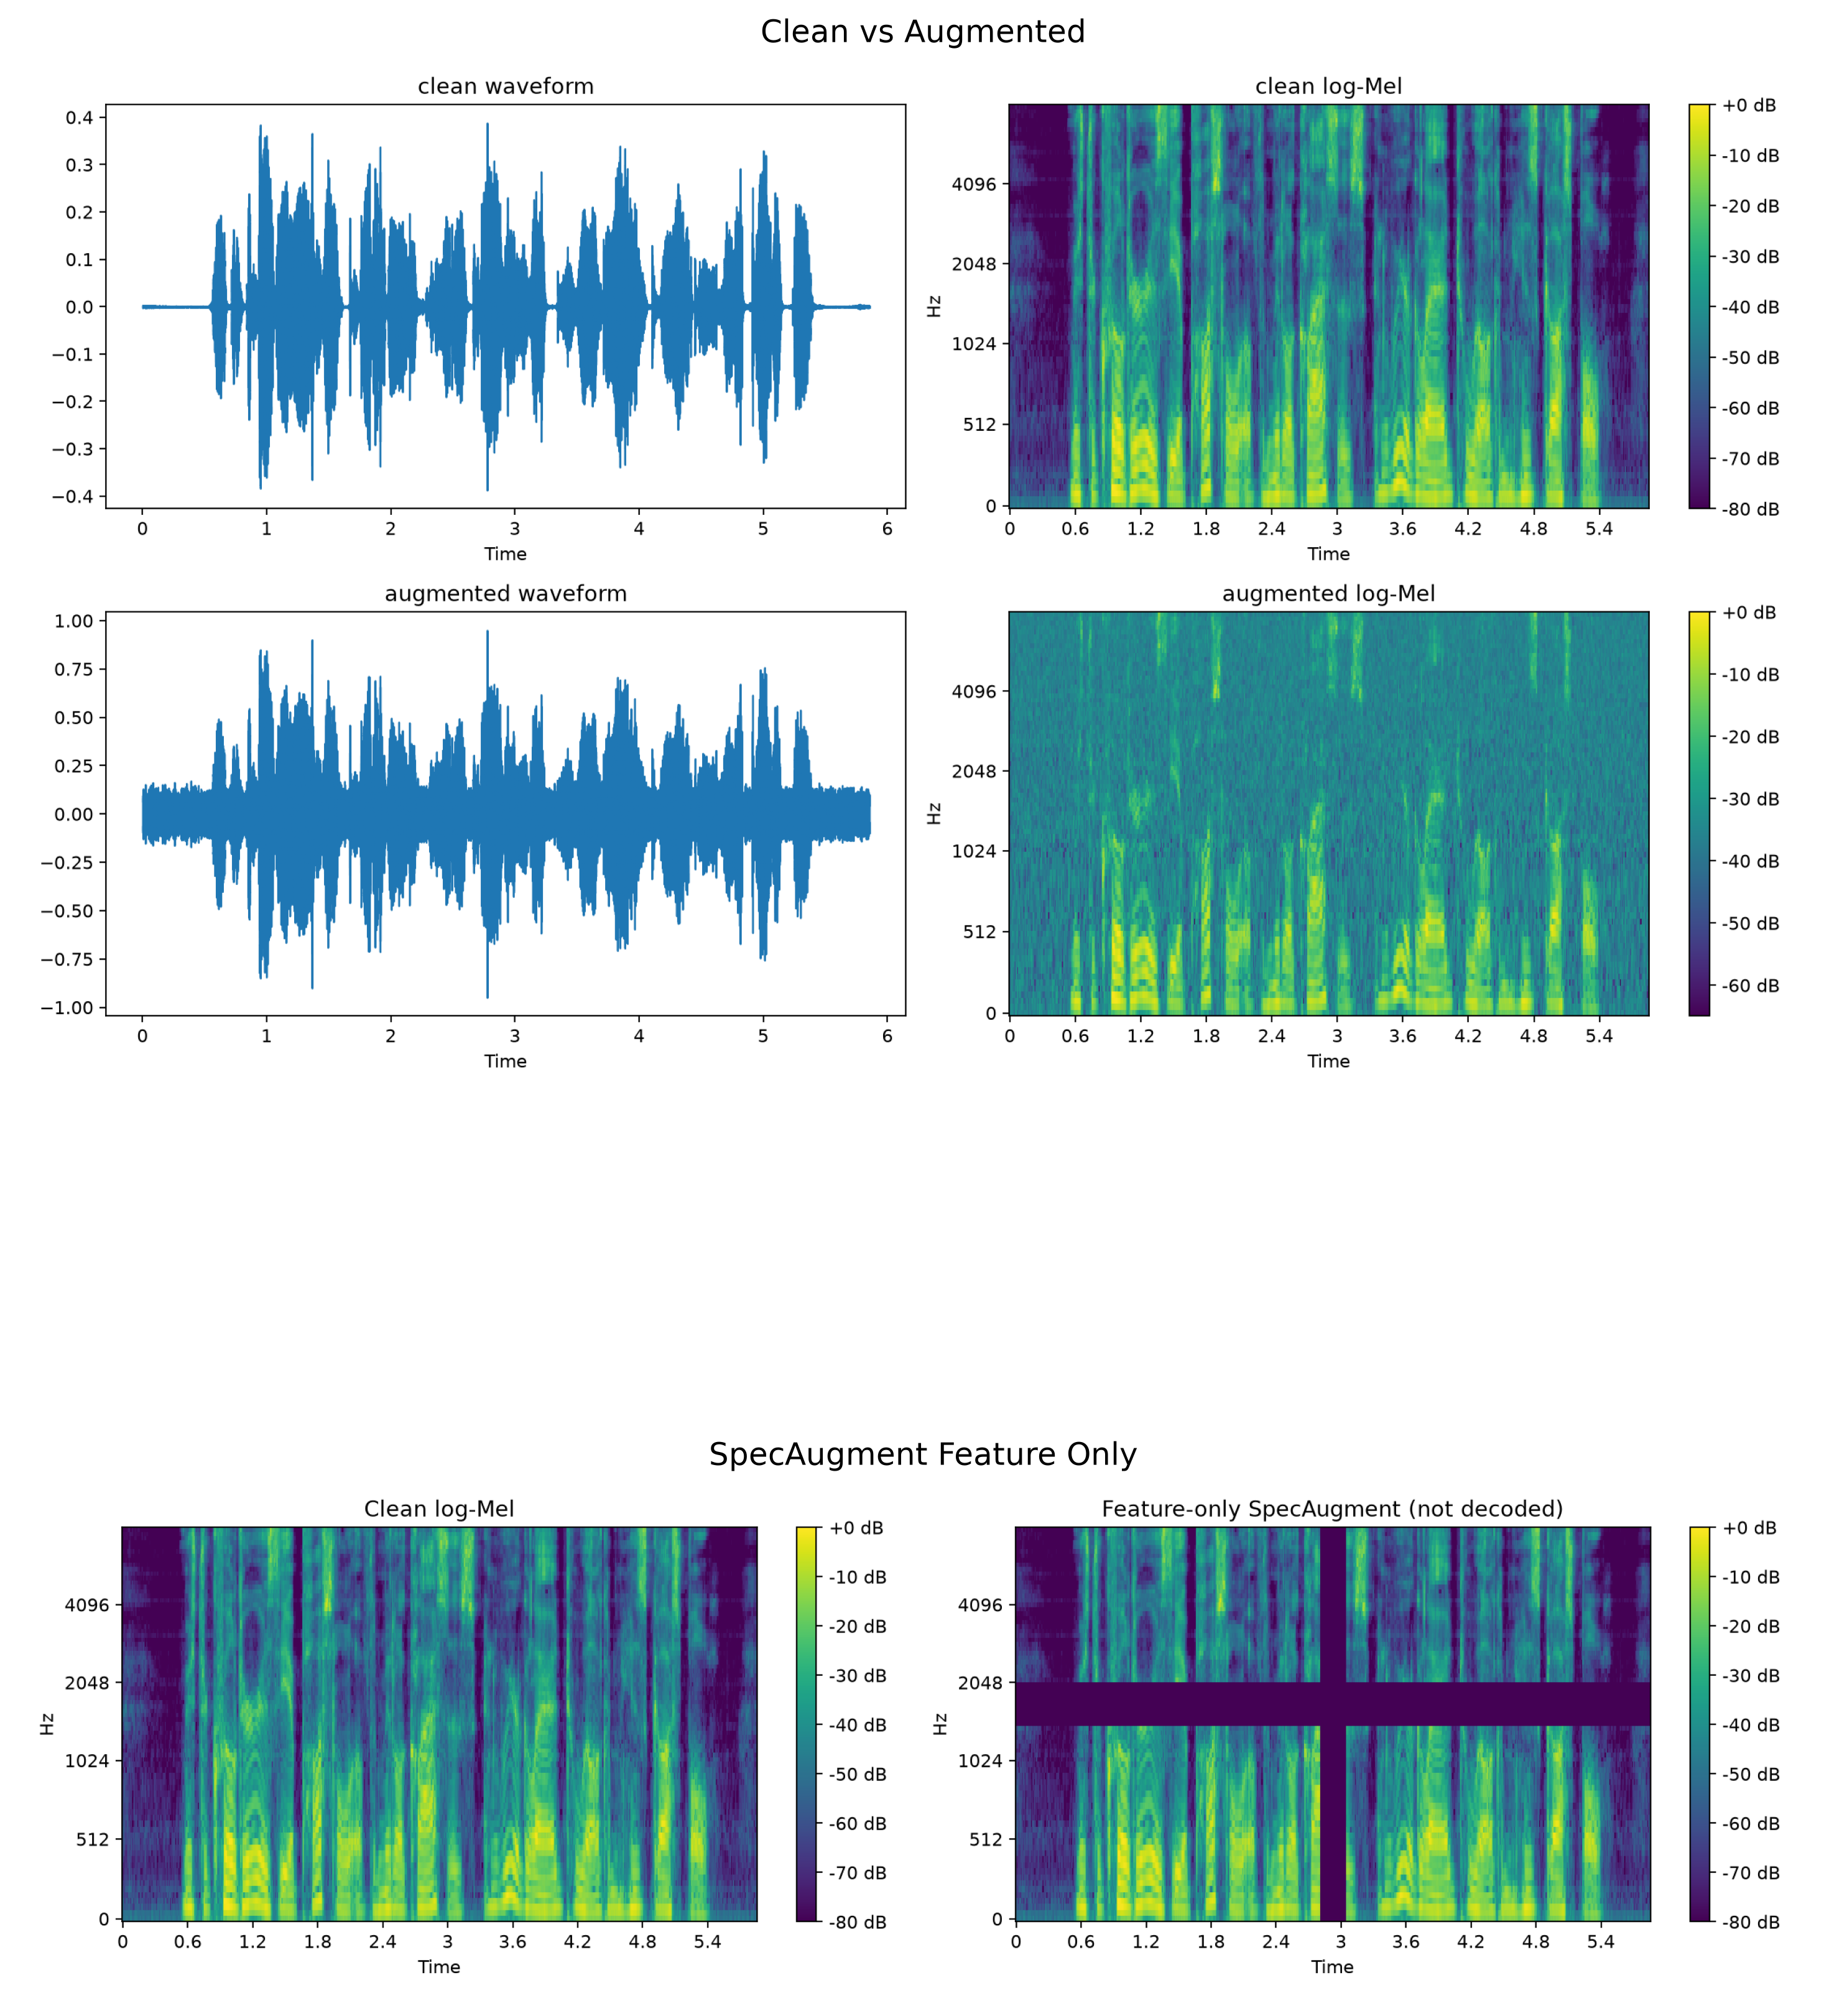

In [4]:
fig, axes = plt.subplots(
    2, 1, figsize=(10, 14), gridspec_kw={"height_ratios": [1.5, 1]}
)

# Отображение первого изображения (делаем его крупнее)
axes[0].imshow(mpimg.imread(fig_dir / "clean_vs_augmented.png"))
axes[0].axis("off")
axes[0].set_title("Clean vs Augmented", fontsize=12)

# Отображение второго изображения
axes[1].imshow(mpimg.imread(fig_dir / "specaugment_feature_only.png"))
axes[1].axis("off")
axes[1].set_title("SpecAugment Feature Only", fontsize=12)

plt.tight_layout()
plt.show()

Мы получили два изображения сигнала и спектрограммы.
В первой паре у нас показано воздействие шума, который мы более подробно разбирали в прошлой работе.

На второй - маскирование по частотной и временной осям, когда часть спектрограммы зануляется.
Маски позволяют спрятать часть сигнала.
В отличие от первой работы, они работают как аугментация только по спектрограммному представлению аудио (хотя по времени аудио сигнал тоже можно маскировать, просто занулив его).
Я предполагаю, что в случае маленьких регионов маскирования, информацию можно частично восстановить за счёт того, что STFT обычно идёт с пересечением сигнала

### 1. Выберите пару аугментаций, и проанализируйте, как они влияют на сигнал (поможет построить графики, подобные clean_vs_augmented.png). Какие два видимые изменения вы наблюдаете в волновой форме и/или log-Mel представлении?

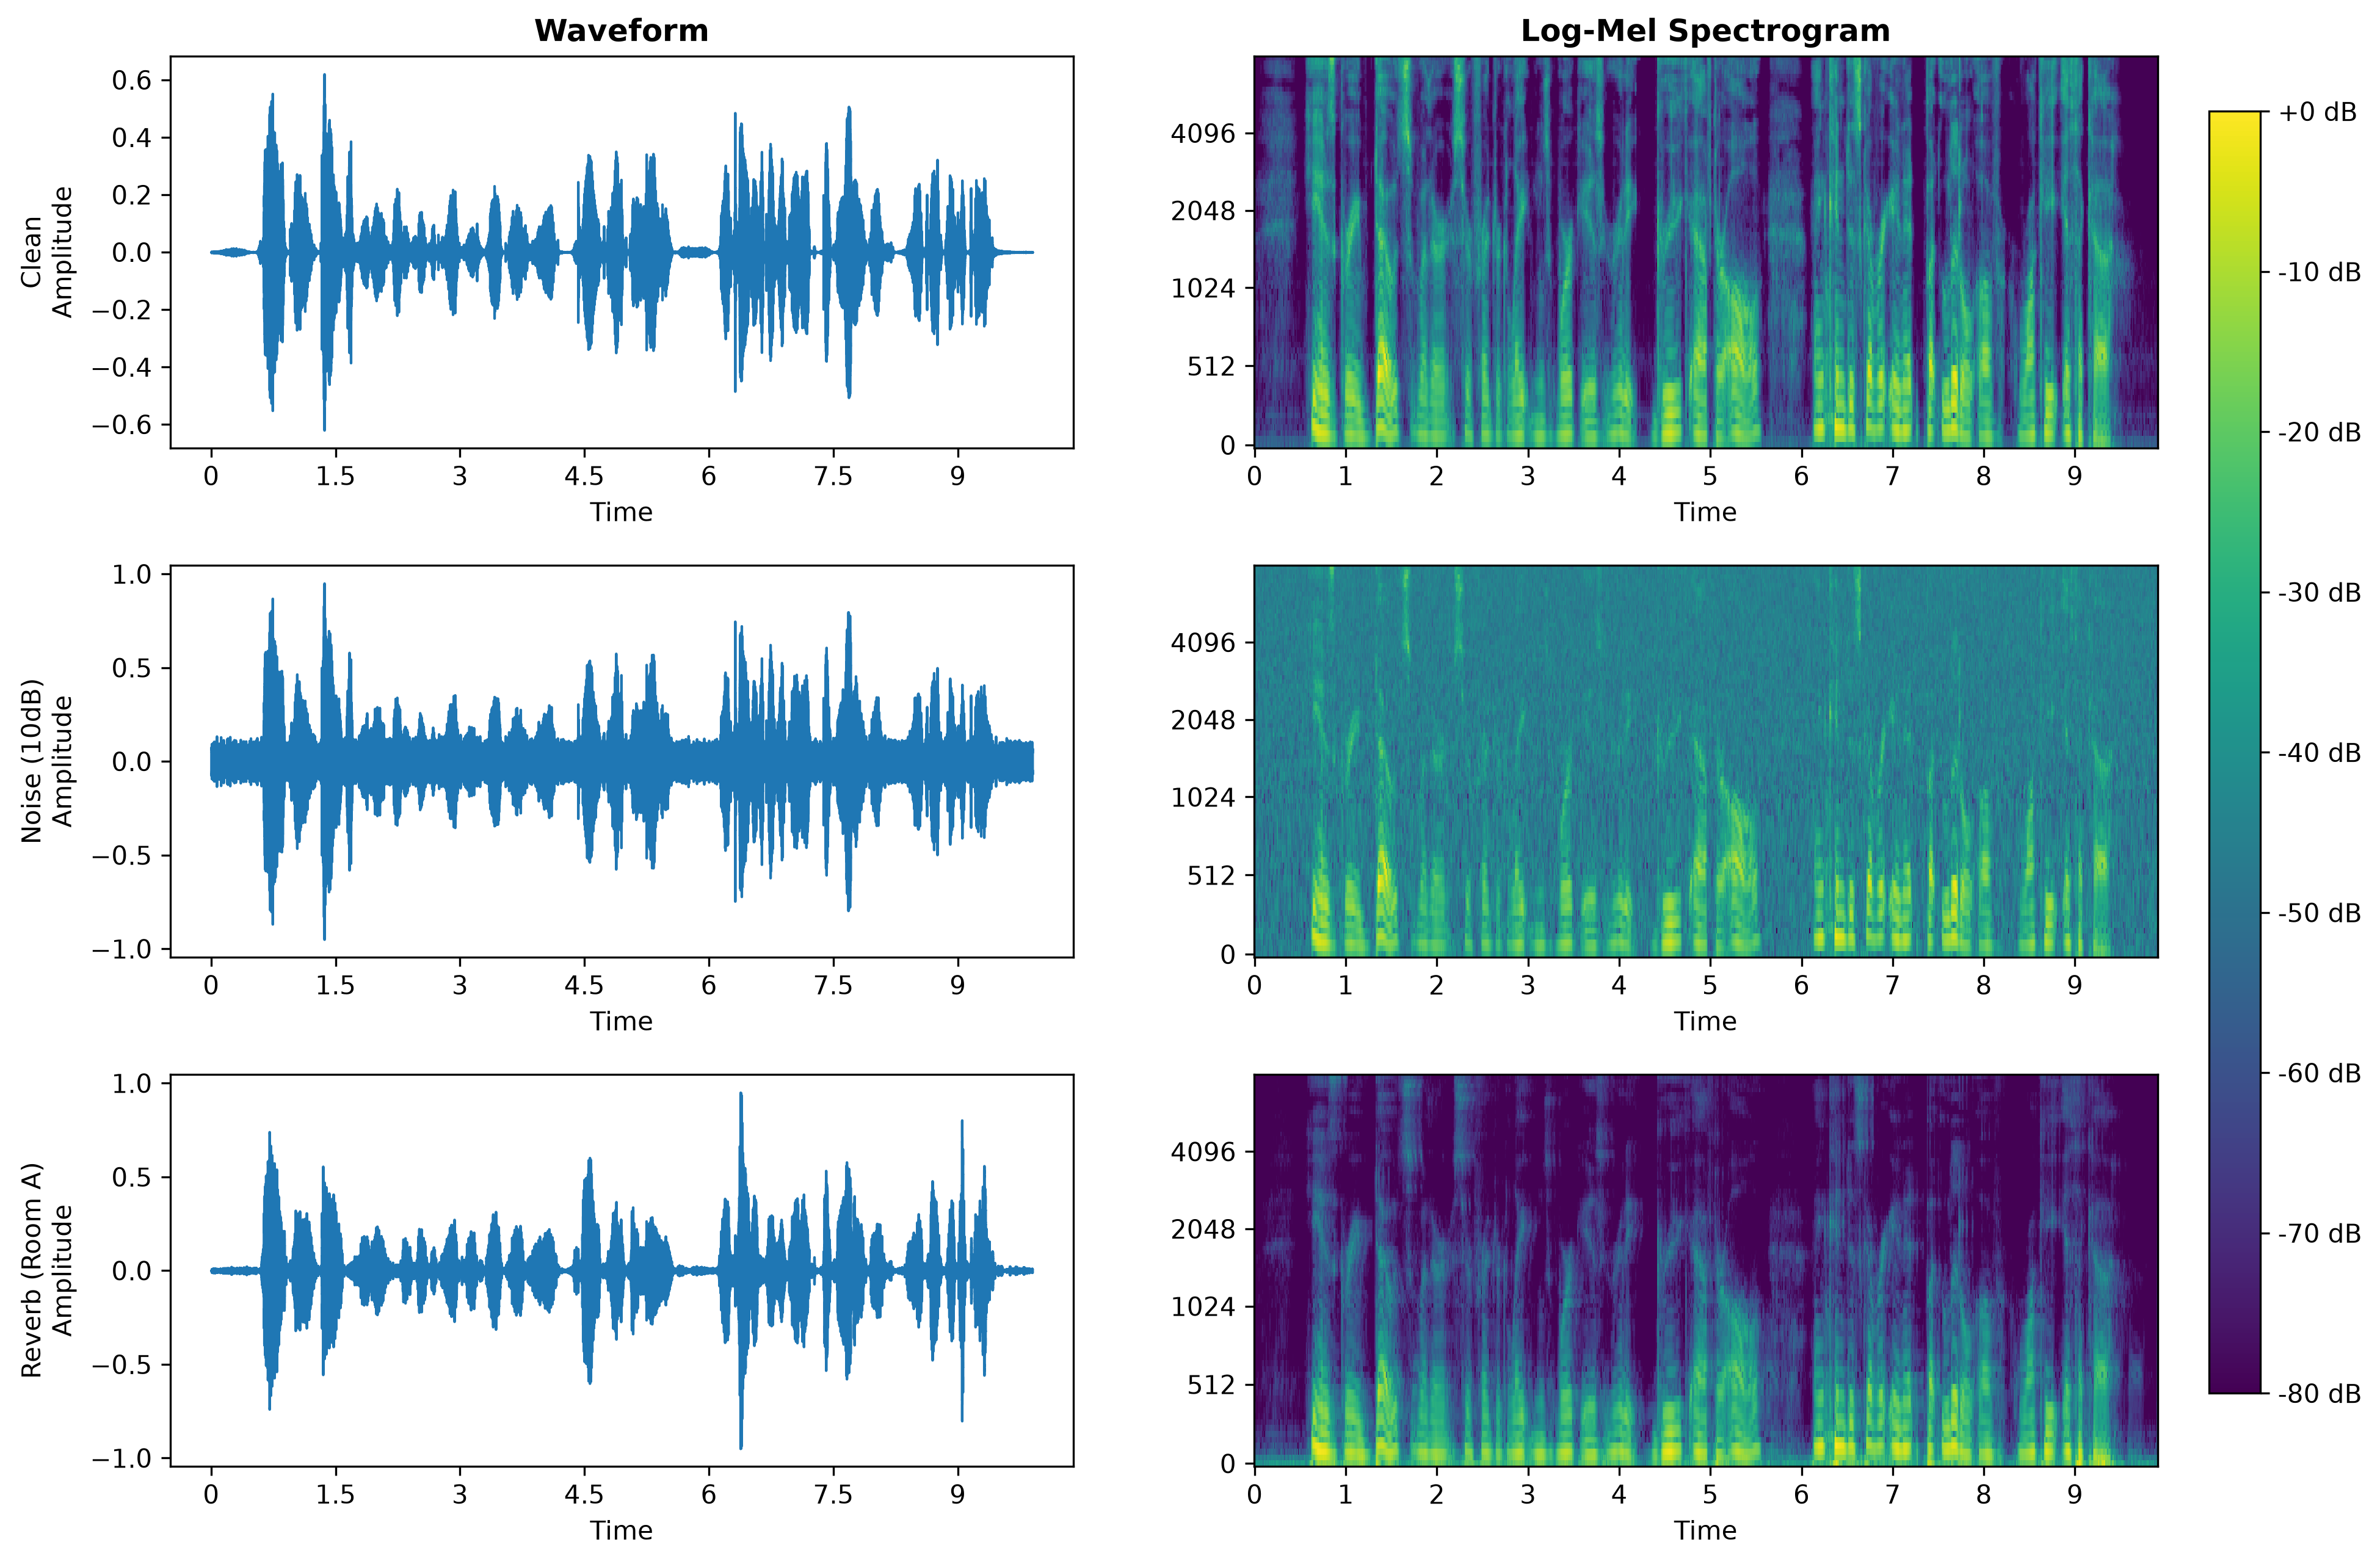

In [5]:
audio_name = "1272-128104-0003"

files = {
    "Clean": aug_dir / f"{audio_name}__clean.wav",
    "Noise (10dB)": aug_dir / f"{audio_name}__noise_10db.wav",
    "Reverb (Room A)": aug_dir / f"{audio_name}__reverb_room_a.wav",
}


def log_mel(audio: np.ndarray, sample_rate: int) -> np.ndarray:
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sample_rate,
        n_fft=400,
        hop_length=160,
        win_length=400,
        n_mels=80,
        fmin=20,
        fmax=7600,
    )
    return librosa.power_to_db(mel, ref=np.max)


# Removed sharex=True so each row scales properly to its own audio duration
fig, axes = plt.subplots(3, 2, figsize=(14, 10))

img = None
for row, (label, path) in enumerate(files.items()):
    y, sr = librosa.load(path, sr=16000, mono=True)

    # Waveform (Left Column)
    librosa.display.waveshow(y, sr=sr, ax=axes[row, 0])
    axes[row, 0].set_ylabel(f"{label}\nAmplitude", fontsize=10)
    if row == 0:
        axes[row, 0].set_title("Waveform", fontsize=12, fontweight="bold")

    # Log-Mel Spectrogram (Right Column)
    img = librosa.display.specshow(
        log_mel(y, sr),
        sr=sr,
        hop_length=160,
        x_axis="time",
        y_axis="mel",
        ax=axes[row, 1],
        cmap="viridis",
    )
    if row == 0:
        axes[row, 1].set_title("Log-Mel Spectrogram", fontsize=12, fontweight="bold")

    # Clear redundant y-axis label for spectrograms
    axes[row, 1].set_ylabel("")

# Add a single shared colorbar on the right side of the figure
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(img, cax=cbar_ax, format="%+2.0f dB")

# Adjust layout to make room for the shared colorbar
fig.subplots_adjust(right=0.9, hspace=0.3)
plt.show()

В качестве пар были выбраны шум в 10db и RIR.
По сигналу разница с шумом в повышение амплитуды в зонах тишины, а у RIR'а изменение некоторых пиков, что на глаз плохо различимо.
По спеке шумы полностью покрыли весь рисунок, а у RIR - прореживание верхних частот.

### 2. Сравните аугментацию реверберацией room_a с аугментацией шумом (snr выберете сами). Какое видимое различие согласуется с временным размыванием, а не с простым аддитивным маскированием?

По факту они и были выбраны в прошлой ячейке.

Шум делает своеобразное маскирование, но в отличие от изначальной аугментации - маскирование не зануление, а наоборот прибавление.
Он по всей площади спектрограммы добавляет сигнал, который скрывает паузы и тихие семплы.
При это громкие семыл всё ещё остаются видны, пусть и хуже.

С временным размыванием согласуется RIR, поскольку из-за отражений сигнала по оси x появлется своеобразный остаточный шлейф.


### 3. Сравните длительности аудио 0.9× и 1.1× с исходыми. Как каждый фактор влияет на длительность и почему одного изменения длительности недостаточно для предсказания как себя поведёт WER?

In [6]:
agg = pd.read_csv("outputs/results/aggregate_results.csv")
conditions = ["clean", "speed_0.9x", "speed_1.1x"]

agg[agg["condition"].isin(conditions)][["condition", "mean_wer"]]

,condition,mean_wer
0,clean,0.083958
5,speed_0.9x,0.083958
6,speed_1.1x,0.058958


In [7]:
rows = []
for cond in conditions:
    info = sf.info(aug_dir / f"{audio_name}__{cond}.wav")
    rows.append(
        {
            "condition": cond,
            "duration_s": round(info.duration, 3),
        }
    )

pd.DataFrame(rows)

,condition,duration_s
0,clean,9.9
1,speed_0.9x,11.0
2,speed_1.1x,9.0


Сюрприз - каждый фактор влияет на итоговую длительность (сколько семплов представляют сигнал).

Изменения длительность недостаточно, потому что мы не имеем представление об изначальном аудио.
Там может быть как диктор, который тараторит, как и разговаривающий как черепаха.
От этого изменение скорости по разному может влиять на итоговую точность распознавания.
Это же распространяется не только на речь, но и на фоновые шумы, которые могут искажаться при изменение скорости.

### 4. Какие области скрыты временными и частотными масками в specaugment_feature_only.png? Предположите, почему такая аугментация может быть полезной для обучения систем ASR?

Маскироание по времени - семплы 483–506; Маскирование по частоте - полосы 35–44


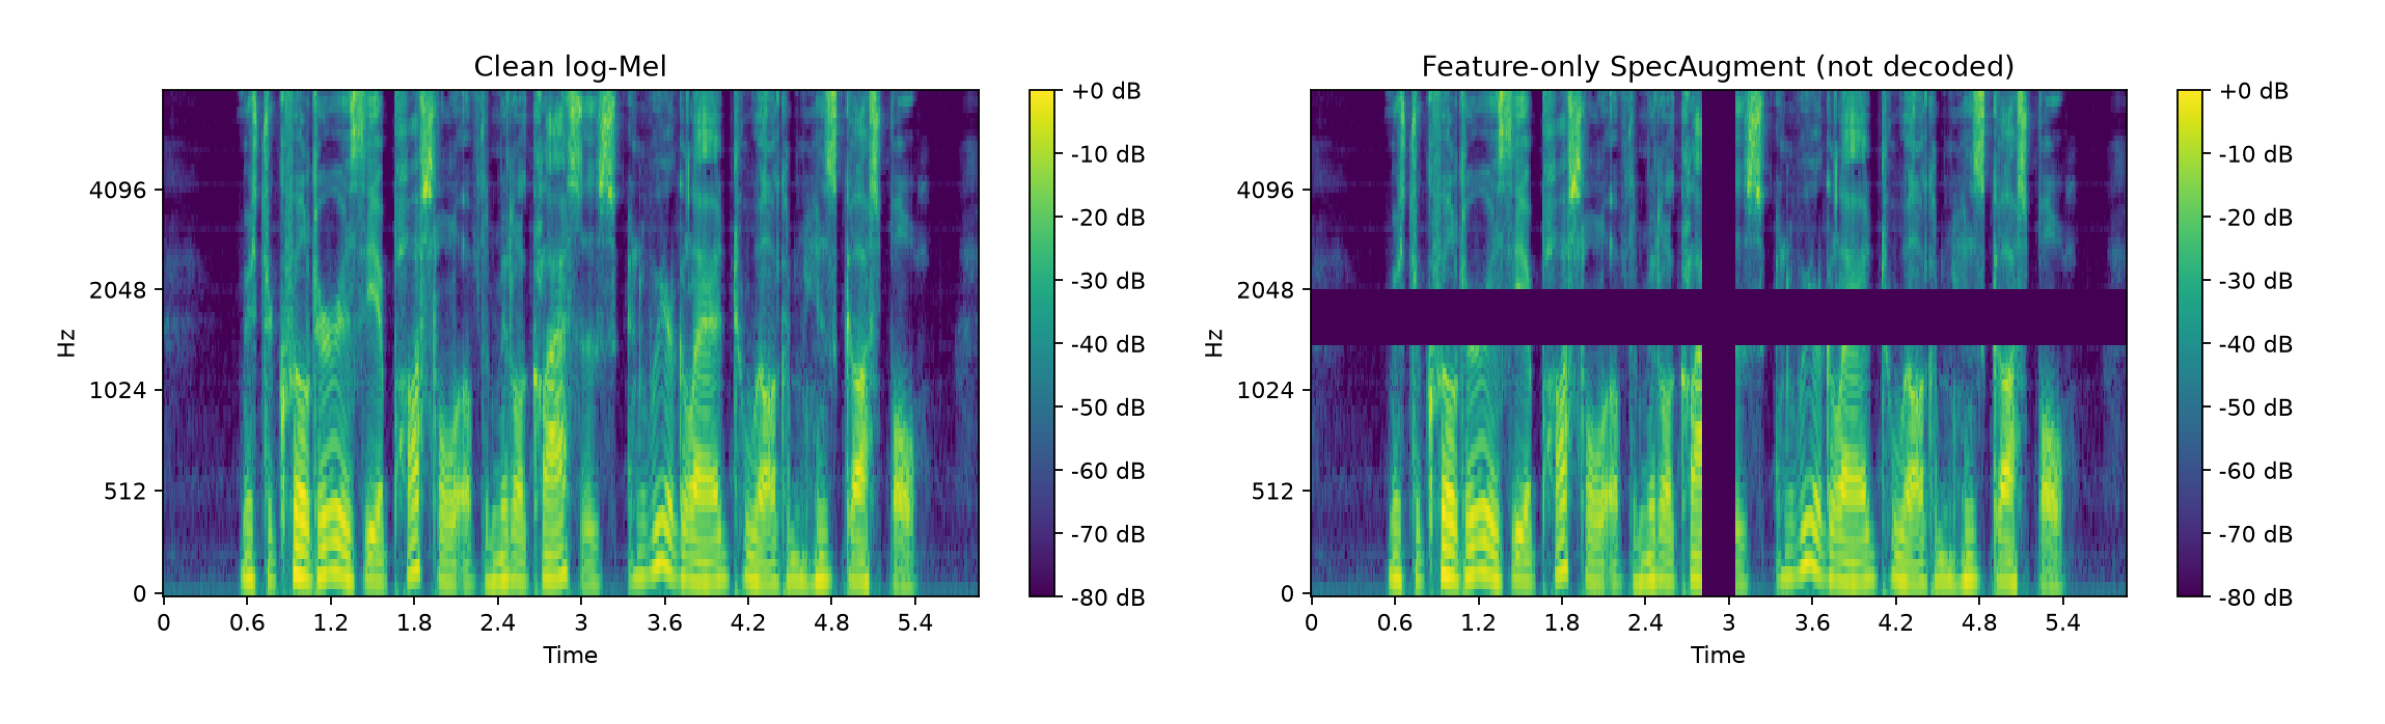

In [8]:
sys.path.append(str(Path("scripts").resolve()))
from plot_augmentation_features import log_mel, specaugment

audio_path = aug_dir / f"{audio_name}__clean.wav"

clean, sr = librosa.load(audio_path, sr=16000, mono=True)
clean_mel = log_mel(clean, sr)
_, meta = specaugment(clean_mel)

time_start = meta["time_start"]
time_width = meta["time_width"]
freq_start = meta["frequency_start"]
freq_width = meta["frequency_width"]

time_frames = list(range(time_start, time_start + time_width))
freq_bands = list(range(freq_start, freq_start + freq_width))

hop_length = 160
time_seconds = [f * hop_length / sr for f in time_frames]

freqs = librosa.mel_frequencies(n_mels=clean_mel.shape[0], fmin=20, fmax=7600)
freq_hz_lo = freqs[freq_start]
freq_hz_hi = freqs[min(freq_start + freq_width, len(freqs) - 1)]

print(
    f"Маскироание по времени - семплы {time_start}–{time_start + time_width - 1}; "
    f"Маскирование по частоте - полосы {freq_start}–{freq_start + freq_width - 1}"
)

plt.figure(figsize=(10, 6))
plt.imshow(mpimg.imread(fig_dir / "specaugment_feature_only.png"))
plt.axis("off")
plt.show()

Скрыты семплы 483-506 по времени и полосы 35-44 по частотам, что равняется примерно 3 секунде аудио и 1800-2048 полоскам соотетственно по графику.

Данные аугментации требуются как и остальные в целом для повышения устойчивости.
Через маскирование по времени мы можем помогать адаптироваться к прерываниям сигнала, когда у системы записи может случиться провисание, из-за чего часть сигнала потеряется. По частоте мы скорее адаптируемся к ресемплингу, когда частотная информация может отсутствовать в изначальном сигнале

### 5. Для одного тестового примера сравните результаты распознавания чистого сигнала с результатами двух его аугментированных вариантов. Укажите WER, CER и RTF для всех трёх аудио. Какая метрика изменяется сильнее всего в выбранном сравнении? Как думаете, почему?

In [9]:
agg = pd.read_csv("outputs/results/per_item_results.csv")

agg[
    (agg["item_id"] == audio_name)
    & (agg["condition"].isin(["clean", "noise_10db", "reverb_room_a"]))
][["condition", "reference_normalized", "hypothesis_normalized", "wer", "cer", "rtf"]]

,condition,reference_normalized,hypothesis_normalized,wer,cer,rtf
14,clean,he has grave doubts whether sir frederick leig...,he has grave doubts whether sir frederick layt...,0.041667,0.030075,0.041282
16,noise_10db,he has grave doubts whether sir frederick leig...,he has great doubts whether sir frederick leig...,0.166667,0.082707,0.041532
18,reverb_room_a,he has grave doubts whether sir frederick leig...,he has grave doubts whether sir frederick layt...,0.125000,0.052632,0.043039


Ожидаемо - чистый сигнал дал науилучшую метрику качества распознавания, поскольку изначальный сигнал не был ничем искажён.
Сильнее всего изменяется WER - в 3-4 раза.
Случается это по вышеописанным причинам, что тихие семплы растворяются при добавление шума.
Проседание же у реверберации получается за счёт добавление эха.

RTF, что логично, особо не изменятеся, поскольку сложность обработки одного аудио для всех трёх случаев одинаковая с одинаковыми преобразованиями уже аугментированного аудио.
Разница в RTF должна из себя представлять просто погрешность.

### 6. Определите вариант аугментации с наибольшим агрегированным mean_wer в aggregate_results.csv. Укажите его имя, агрегированные mean_wer, mean_cer и сравнение текстовок для одного тестового примера с этой аугментацией. Как вы думаете, почему такая аугментация сильнее всего сказывается на работе ASR модели?

In [10]:
agg = pd.read_csv("outputs/results/aggregate_results.csv")

worst = agg.loc[agg["mean_wer"].idxmax()]
clean = agg.loc[agg["condition"] == "clean"].iloc[0]

comparison = pd.DataFrame([clean, worst])[
    ["condition", "mean_wer", "mean_cer", "mean_rtf"]
]
comparison

,condition,mean_wer,mean_cer,mean_rtf
0,clean,0.083958,0.049979,0.060693
1,noise_0db,0.753230,0.427322,0.084864


In [ ]:
per_item = pd.read_csv("outputs/results/per_item_results.csv")

for cond in ["clean", "noise_0db"]:
    row = per_item[
        (per_item["item_id"] == audio_name) & (per_item["condition"] == cond)
    ].iloc[0]
    print(
        f"{cond}\nЭталон: {row['reference_normalized']}\nТекстовка: {row['hypothesis_normalized']}\nWER = {row['wer']}, CER = {row['cer']}, RTF = {row['rtf']}\n"
    )

clean
Эталон: he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca
Текстовка: he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of rocky ithaca
WER = 0.041667, CER = 0.030075, RTF = 0.041282

noise_0db
Эталон: he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca
Текстовка: he has great notes for that so he's going to make him work with me he's beat after all and he can discover in it a little while he isn't hurt
WER = 0.833333, CER = 0.518797, RTF = 0.042549



Такая разница в WER получается, поскольку 0 SNR означает, что мощности сигнала и шума равны.
Соответственно тихие звуки, границы слов и прочая информация просто стирается.

### 7. Найдите такой тип аугментации, для которого WER и CER сигнализируют о разном уровне влияния на систему ASR (скажем WER деградирует значительно, но CER увеличивается не очень сильно). Рассмотрите текстовки, предположите, почему наблюдается такое поведение?.

In [12]:
agg["wer_cer_ratio"] = agg["mean_wer"] / agg["mean_cer"]
agg[["condition", "mean_wer", "mean_cer", "wer_cer_ratio"]].sort_values(
    "wer_cer_ratio", ascending=False
)

,condition,mean_wer,mean_cer,wer_cer_ratio
4,reverb_room_a,0.120625,0.060840,1.982659
3,noise_20db,0.128958,0.070029,1.841494
2,noise_10db,0.148958,0.081784,1.821359
1,noise_0db,0.753230,0.427322,1.762675
5,speed_0.9x,0.083958,0.047959,1.750620
0,clean,0.083958,0.049979,1.679866
6,speed_1.1x,0.058958,0.038559,1.529033


In [ ]:
target_cond = (
    agg[agg["condition"] != "clean"]
    .sort_values("wer_cer_ratio", ascending=False)["condition"]
    .iloc[0]
)

print(f"\n--- Сравнение текстовок для условия: {target_cond} ---")
for cond in ["clean", target_cond]:
    row = per_item[
        (per_item["item_id"] == audio_name) & (per_item["condition"] == cond)
    ].iloc[0]
    print(f"[{cond}]")
    print("Эталон:   ", row["reference_normalized"])
    print("Гипотеза: ", row["hypothesis_normalized"])
    print(f"WER = {row['wer']:.3f}, CER = {row['cer']:.3f}\n")


--- Сравнение текстовок для условия: reverb_room_a ---
[clean]
Эталон:    he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca
Гипотеза:  he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of rocky ithaca
WER = 0.042, CER = 0.030

[reverb_room_a]
Эталон:    he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca
Гипотеза:  he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of wonky ithaka
WER = 0.125, CER = 0.053



Хуже всего ситуация у RIR'a.
Это связано с размыванием временной границы у слов, дублирование фонем.
Так у нас `rocky` превращается в `wonky`.
Эта замена в двух буквах приводит к повышению WER сильнее, чем CER, так как правильные буквы всё ещё остались в слове.

### 8. Для идентичной ошибки/ошибок распознавания при разных типах аугментации приведите эталон и гипотезу (или их фрагменты). Является ли правдоподобным объяснением акустическое маскирование, временное размывание, сегментация/тайминг или предпочтение декодера/языковой модели? Укажите, какие у вас есть предположения, относительно таких ошибок распознавания.

In [14]:
pivot = per_item.pivot_table(index="item_id", columns="condition", values="wer")

for item, row in pivot.iterrows():
    if pd.isna(row["clean"]):
        continue
    matches = [c for c in pivot.columns if c != "clean" and row[c] == row["clean"]]
    if matches:
        print(f"{item}: clean WER = {row['clean']:.4f}, совпадает с {matches}")

1272-128104-0000: clean WER = 0.0588, совпадает с ['noise_10db', 'noise_20db', 'reverb_room_a', 'speed_0.9x', 'speed_1.1x']
1272-128104-0001: clean WER = 0.1000, совпадает с ['speed_0.9x', 'speed_1.1x']
1272-128104-0003: clean WER = 0.0417, совпадает с ['speed_0.9x']
1272-128104-0006: clean WER = 0.1667, совпадает с ['noise_10db', 'noise_20db', 'reverb_room_a', 'speed_0.9x']
1272-128104-0007: clean WER = 0.0526, совпадает с ['noise_10db', 'noise_20db', 'reverb_room_a', 'speed_0.9x', 'speed_1.1x']


In [ ]:
print(
    "Orig:",
    per_item[per_item["item_id"] == "1272-128104-0007"].iloc[0]["reference_normalized"],
)
per_item[per_item["item_id"] == "1272-128104-0007"][
    ["condition", "hypothesis_normalized", "wer"]
]

Orig: painting he tells us is of a different quality to mathematics and finish in art is adding more fact


,condition,hypothesis_normalized,wer
28,clean,painting he tells us is of a different quality to mathematics and finish in art is adding more effect,0.052632
29,noise_20db,painting he tells us is of a different quality to mathematics and finish in art is adding more effect,0.052632
30,noise_10db,painting he tells us is of a different quality to mathematics and finish in art is adding more effect,0.052632
31,noise_0db,the painting details are squeezed of a different quality from mathematics and finished in art is adding more effect,0.421053
32,reverb_room_a,painting he tells us is of a different quality to mathematics and finish in art is adding more effect,0.052632
33,speed_0.9x,painting he tells us is of a different quality to mathematics and finish in art is adding more factor,0.052632
34,speed_1.1x,painting he tells us is of a different quality to mathematics and finish in art is adding more effect,0.052632


Для аудио `1272-128104-0007` 6 из 7 аудио имеют идентичный WER c изначальным аудио.
Во всех этих случаях модель неправильно распознала слово `fact` как `effect` или `factor`.

Касательно `effect` действительно языковая модель декодирования может играть наибольшую роль в сторону распознавания этого слова.
is adding more effect для меня звучит как более грамматически вероятная конструкция, чем со словом fact.
Факт того, что при замедление аудио модель растягивает слово до factor также может говорить о доминирование языкового декодера в такого рода ошибки, поскольку добавить фактор (опять же для меня) также звучит как более вероятная конструкция.

### 9. Как вы думаете, всегда ли более высокий WER в нашем бенчмарке, есть индикатор того, что такая аугментация - универсальная ASR? Назовите два фактора в этой лабораторной работе, которые не позволяют сделать такой вывод.

Высокий WER на нашем бенчмарке - это высокий WER на нашем бенчмарке.
Модели часто имеют разный WER в зависимости от доменного набора данных.
Судя же добавляются особенности спикеров.

Возможные факторы:
- У нас мало данных. Чтобы говорить, что аугментации универсальны - нам нужен универсальный набор данных с разными доменами, спикерами, акцентами и прочими вещами. У нас число аудио - 5.
- Мы проверяем всё на одной модели. Атаки могут быть не переносимы даже между моделями, которые имеют одинаковую архитектуру, но разные данные. Говорить что-то только после прогона на маленьком виспере - рано.
